In [1]:
# Standard Python modules
import os, sys
import glob
import numpy as np
import pandas as pd
import xarray as xr
import re
import datetime

# import personal modules
# Path to modules
sys.path.append('../modules')
# Import my modules
import global_vars
from utils import select_months_ds, select_months_df, get_startmon_and_endmon

path_to_data = '/cw3e/mead/projects/cwp162/data/'
path_to_out  = '../out/'       # output files (numerical results, intermediate datafiles) -- read & write
path_to_figs = '../figs/'      # figures

## Load tARgetv4 AR data
fname = path_to_data + 'downloads/globalARcatalog_ERA5_1940-2024_v4.0.nc'
ds = xr.open_dataset(fname)
ds = ds.isel(lev=0, ens=0)
ds = ds.assign_coords({"lon": (((ds.lon + 180) % 360) - 180)}) # Convert DataArray longitude coordinates from 0-359 to -180-179
latmin, latmax, lonmin, lonmax = 10., 70., -140., -80.
ds = ds.sel(lat=slice(latmax, latmin), lon=slice(lonmin, lonmax))
ds = ds.sel(time=slice('2000-01-01', '2023-12-31'))

## resample ARDT to daily
ds = ds.kidmap.resample(time='1D').max()

## Load PRISM precipitation dataset and add water year information
ssn = 'NDJFMA'
start_mon, end_mon = get_startmon_and_endmon(ssn)
## load PRISM watershed precip dataset to get list of HUC8s
fname = path_to_data + 'preprocessed/PRISM/PRISM_HUC8_CO_sp.nc'
PRISM = xr.open_dataset(fname)
PRISM = PRISM.rename({"date": "time"})
## add water year to data as coordinate
water_year = (PRISM.time.dt.month >= 10) + PRISM.time.dt.year
PRISM.coords['water_year'] = water_year
HUC8_ID_lst = PRISM.HUC8.values ## get list of HUC8 IDs

## Subset the AR dataset to the centroid of the HUC8
# Get centroid locations for all HUC8s
lat_sel = PRISM.lat
lon_sel = PRISM.lon

# Select nearest AR grid cell for each HUC8
AR_at_HUC8 = ds.sel(
    lat=lat_sel,
    lon=lon_sel,
    method="nearest"
)


AR_at_HUC8

<xarray.DataArray 'kidmap' (time: 8766, HUC8: 92)> Size: 6MB
array([[2.0000101e+11, 2.0000101e+11,           nan, ...,           nan,
        2.0000101e+11,           nan],
       [          nan,           nan,           nan, ..., 2.0000101e+11,
        2.0000101e+11,           nan],
       [          nan,           nan,           nan, ...,           nan,
                  nan,           nan],
       ...,
       [          nan,           nan,           nan, ...,           nan,
                  nan,           nan],
       [          nan,           nan,           nan, ...,           nan,
                  nan,           nan],
       [          nan,           nan,           nan, ...,           nan,
                  nan,           nan]])
Coordinates:
    lat      (HUC8) float64 736B 37.25 36.75 38.75 38.5 ... 37.5 38.5 38.0 39.75
    lev      float64 8B 0.0
    ens      float64 8B 1.0
    lon      (HUC8) float64 736B -108.5 -108.5 -108.2 ... -101.8 -101.5 -101.5
  * time     (time) datetime64[ns] 70kB 2000-01-01 2000-01-02 ... 2023-12-31
  * HUC8     (HUC8) <U8 3kB '14080107' '14080105' ... '11030001' '10250013'
Attributes:
    long_name:  Track: ID
    units:      none

In [2]:
## create a new dataset with PRISM prec values for the HUC8, extreme binary, AR indication, and water year
ds_all = xr.Dataset(
    data_vars=dict(
        precipitation = PRISM.prec,
        extreme       = PRISM.extreme,
        AR            = AR_at_HUC8,
    ),
    coords=dict(
        time        = PRISM.time,
        HUC8        = PRISM.HUC8,
        water_year  = PRISM.water_year,
    ),
)
ds_all

<xarray.Dataset> Size: 20MB
Dimensions:        (time: 8766, HUC8: 92)
Coordinates:
  * time           (time) datetime64[ns] 70kB 2000-01-01 ... 2023-12-31
  * HUC8           (HUC8) <U8 3kB '14080107' '14080105' ... '10250013'
    water_year     (time) int64 70kB 2000 2000 2000 2000 ... 2024 2024 2024 2024
    lat            (HUC8) float64 736B 37.25 36.75 38.75 ... 38.5 38.0 39.75
    lev            float64 8B 0.0
    ens            float64 8B 1.0
    lon            (HUC8) float64 736B -108.5 -108.5 -108.2 ... -101.5 -101.5
Data variables:
    precipitation  (HUC8, time) float64 6MB ...
    extreme        (HUC8, time) int64 6MB ...
    AR             (time, HUC8) float64 6MB 2e+11 2e+11 nan nan ... nan nan nan

In [3]:
ARIDs = ds_all.where(ds_all.AR >= 0)
ARIDs

<xarray.Dataset> Size: 20MB
Dimensions:        (HUC8: 92, time: 8766)
Coordinates:
  * time           (time) datetime64[ns] 70kB 2000-01-01 ... 2023-12-31
  * HUC8           (HUC8) <U8 3kB '14080107' '14080105' ... '10250013'
    water_year     (time) int64 70kB 2000 2000 2000 2000 ... 2024 2024 2024 2024
    lat            (HUC8) float64 736B 37.25 36.75 38.75 ... 38.5 38.0 39.75
    lev            float64 8B 0.0
    ens            float64 8B 1.0
    lon            (HUC8) float64 736B -108.5 -108.5 -108.2 ... -101.5 -101.5
Data variables:
    precipitation  (HUC8, time) float64 6MB 1.395 nan nan nan ... nan nan nan
    extreme        (HUC8, time) float64 6MB 0.0 nan nan nan ... nan nan nan nan
    AR             (time, HUC8) float64 6MB 2e+11 2e+11 nan nan ... nan nan nan

In [4]:
ARIDs

<xarray.Dataset> Size: 20MB
Dimensions:        (HUC8: 92, time: 8766)
Coordinates:
  * time           (time) datetime64[ns] 70kB 2000-01-01 ... 2023-12-31
  * HUC8           (HUC8) <U8 3kB '14080107' '14080105' ... '10250013'
    water_year     (time) int64 70kB 2000 2000 2000 2000 ... 2024 2024 2024 2024
    lat            (HUC8) float64 736B 37.25 36.75 38.75 ... 38.5 38.0 39.75
    lev            float64 8B 0.0
    ens            float64 8B 1.0
    lon            (HUC8) float64 736B -108.5 -108.5 -108.2 ... -101.5 -101.5
Data variables:
    precipitation  (HUC8, time) float64 6MB 1.395 nan nan nan ... nan nan nan
    extreme        (HUC8, time) float64 6MB 0.0 nan nan nan ... nan nan nan nan
    AR             (time, HUC8) float64 6MB 2e+11 2e+11 nan nan ... nan nan nan

In [5]:
tmp = ARIDs.isel(HUC8=0)
tmp = tmp.where(tmp.AR >= 0, drop=True)
tmp.AR

<xarray.DataArray 'AR' (time: 1176)> Size: 9kB
array([2.00001010e+11, 2.00001131e+11, 2.00001161e+11, ...,
       2.02312031e+11, 2.02312031e+11, 2.02312231e+11])
Coordinates:
  * time        (time) datetime64[ns] 9kB 2000-01-01 2000-01-16 ... 2023-12-23
    HUC8        <U8 32B '14080107'
    water_year  (time) int64 9kB 2000 2000 2000 2000 ... 2024 2024 2024 2024
    lat         float64 8B 37.25
    lev         float64 8B 0.0
    ens         float64 8B 1.0
    lon         float64 8B -108.5
Attributes:
    long_name:  Track: ID
    units:      none

In [9]:
ARID_14080107 = tmp.AR.to_dataframe()

ARID_14080107.to_csv(
    os.path.join(path_to_out, "ARID_14080107.csv"),
    index=True
)

In [6]:
# Subset to NDJFMA
idx = (ds_all.time.dt.month >= 11) | (ds_all.time.dt.month <= 4)
ds_all = ds_all.sel(time=idx)

# compute Total extreme precipitation (denominator)
PRISM_90 = ds_all.where(ds_all.extreme == 1)

PRISM_90WY = (
    PRISM_90.precipitation
    .groupby("water_year")
    .sum("time")
    .sum("water_year")
)
PRISM_90WY

<xarray.DataArray 'precipitation' (HUC8: 92)> Size: 736B
array([ 980.4403 ,  534.2005 , 1006.4613 , 1257.9502 ,  675.4596 ,
       2035.985  ,  744.1534 , 1004.2498 ,  394.1523 ,  234.7114 ,
        764.5213 ,  252.2895 ,  514.0727 ,  489.4805 ,  631.7624 ,
        541.4888 ,  611.1923 ,  753.1339 ,  236.49924,  980.6195 ,
       1759.248  ,  876.3242 , 1384.9049 ,  611.9726 ,  646.7125 ,
        577.6665 , 1037.3635 ,  845.65166,  519.2625 ,  551.6955 ,
        597.5461 ,  754.9268 ,  317.0266 ,  446.4755 ,  780.3857 ,
        410.8028 ,  307.81202,  376.6432 , 2176.583  ,  507.57101,
        421.6363 ,  541.408  , 1273.29613,  833.2102 ,  588.5592 ,
        619.8406 ,  561.5318 ,  670.1572 ,  616.26105,  864.87027,
       2153.2374 , 1473.5613 , 1382.3309 ,  622.0568 ,  429.3249 ,
        862.9532 ,  653.2642 ,  656.0787 ,  645.9791 ,  910.532  ,
        733.6256 ,  946.3863 ,  715.6503 ,  726.8466 ,  274.5586 ,
       2498.0831 , 1041.27972, 1930.9807 ,  516.9261 ,  619.3735 ,
        892.9068 , 2357.9079 , 1267.1702 , 1657.26   ,  899.77979,
        470.88298,  340.0326 , 1371.5546 , 1049.0228 ,  319.6465 ,
        682.5517 ,  519.6416 ,  603.8899 , 1191.7624 ,  863.782  ,
        669.2033 , 2158.6174 , 1132.0204 ,  420.4981 ,  618.0337 ,
        677.7839 ,  680.5552 ])
Coordinates:
  * HUC8     (HUC8) <U8 3kB '14080107' '14080105' ... '11030001' '10250013'
    lat      (HUC8) float64 736B 37.25 36.75 38.75 38.5 ... 37.5 38.5 38.0 39.75
    lev      float64 8B 0.0
    ens      float64 8B 1.0
    lon      (HUC8) float64 736B -108.5 -108.5 -108.2 ... -101.8 -101.5 -101.5

In [6]:
# compute AR-associated extreme precipitation (numerator)
PRISM_AR90 = ds_all.where(
    (ds_all.extreme == 1) & (ds_all.AR > 0)
)

PRISM_AR90WY = (
    PRISM_AR90.precipitation
    .groupby("water_year")
    .sum("time")
    .sum("water_year")
)
PRISM_AR90WY

<xarray.DataArray 'precipitation' (HUC8: 92)> Size: 736B
array([ 748.0773 ,  454.0998 ,  615.3503 ,  721.0857 ,  261.2035 ,
       1166.2589 ,  101.3185 ,  120.0834 ,  131.0388 ,   82.3279 ,
        295.9096 ,   98.1526 ,  368.1605 ,  191.7391 ,  209.2197 ,
        218.2378 ,  391.6795 ,  385.6394 ,   91.30093,  491.6413 ,
        597.0824 ,  544.3784 ,  358.4643 ,  219.9447 ,  339.5921 ,
        341.46   ,  569.6631 ,  320.3503 ,  152.4508 ,  246.5005 ,
        196.8512 ,  294.3756 ,  115.1331 ,  253.5561 ,  645.0484 ,
        191.3311 ,   67.5515 ,  174.7613 , 1680.7041 ,  185.0583 ,
         65.6072 ,  134.3432 ,  413.1189 ,  284.8154 ,  269.4223 ,
        372.8933 ,  328.6778 ,  353.8351 ,  241.6297 ,  209.6103 ,
       1096.0509 ,  569.965  ,  543.5551 ,  204.8869 ,  126.3906 ,
        332.2924 ,  293.4504 ,  354.9477 ,  440.081  ,  448.1339 ,
        304.1579 ,  325.479  ,  367.6282 ,  141.7523 ,  121.5308 ,
       1450.5433 ,  253.38277,  701.6549 ,  318.9131 ,  217.6771 ,
        659.1431 , 1438.9968 , 1010.2567 , 1094.3331 ,  522.9946 ,
        111.1858 ,   78.0745 ,  255.5824 ,  329.6234 ,  107.9109 ,
        395.2161 ,  285.4392 ,  477.5702 ,  836.8902 ,  508.5892 ,
        313.2559 , 1158.2376 ,  280.6823 ,  198.747  ,  413.6415 ,
        440.2237 ,  405.4233 ])
Coordinates:
  * HUC8     (HUC8) <U8 3kB '14080107' '14080105' ... '11030001' '10250013'
    lat      (HUC8) float64 736B 37.25 36.75 38.75 38.5 ... 37.5 38.5 38.0 39.75
    lev      float64 8B 0.0
    ens      float64 8B 1.0
    lon      (HUC8) float64 736B -108.5 -108.5 -108.2 ... -101.8 -101.5 -101.5

In [7]:
fraction90WY = (PRISM_AR90WY / PRISM_90WY) * 100
fraction_df = (
    fraction90WY
    .to_dataframe(name="AR_fraction_extreme_precip")
    .reset_index()
)
fraction_df

,HUC8,lat,lev,ens,lon,AR_fraction_extreme_precip
0,14080107,37.25,0.0,1.0,-108.50,76.300138
1,14080105,36.75,0.0,1.0,-108.50,85.005499
2,14020005,38.75,0.0,1.0,-108.25,61.139986
3,14020002,38.50,0.0,1.0,-107.25,57.322277
4,14050002,40.50,0.0,1.0,-108.25,38.670485
...,...,...,...,...,...,...
87,10190002,39.50,0.0,1.0,-105.25,24.794809
88,11020013,37.50,0.0,1.0,-102.75,47.264661
89,11030002,38.50,0.0,1.0,-101.75,66.928632
90,11030001,38.00,0.0,1.0,-101.50,64.950451


In [8]:
fraction_df.to_csv(
    os.path.join(path_to_out, "AR_fraction_extreme_precip_by_HUC8.csv"),
    index=False
)

In [9]:
df = fraction_df.drop(columns=["lat", "lon", "lev", "ens"])

In [10]:
## import libraries
import sys
import glob
import re

import geopandas as gpd
import cartopy
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
import pandas as pd
import cmocean.cm as cmo
from matplotlib.gridspec import GridSpec

# cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# import personal modules
# Path to modules
sys.path.append('../../modules')
# Import my modules
import global_vars
from plotter import draw_basemap, plot_terrain
from utils import select_months_ds, select_months_df, get_startmon_and_endmon
import customcmaps as ccmap
from load_shapefiles import load_region_shp, load_HUC8
from plot_trajectory_maps import subset_gdf_to_plot

In [11]:
polys = load_HUC8()
regions = load_region_shp(polys)

/home/dnash/miniconda3/envs/SEAK-impacts/lib/python3.12/site-packages/pyogrio/raw.py:198: RuntimeWarning: driver ESRI Shapefile does not support open option CRS
  return ogr_read(


In [12]:
# Perform the join using the 'merge' function
merged_gdf = polys.merge(df, on='HUC8')
merged_gdf

,OBJECTID,TNMID,MetaSource,SourceData,SourceOrig,SourceFeat,LoadDate,GNIS_ID,AreaAcres,AreaSqKm,States,HUC8,Name,Shape_Leng,Shape_Area,geometry,region_name,prec_thres,AR_fraction_extreme_precip
0,1,{75740F8C-AFFA-40B5-908E-4911BCB38D0B},None,None,None,None,2012-06-11,0,513247.49,2077.04,"CO,NM",14080107,Mancos,2.941237,0.210751,"POLYGON ((-108.17534 37.49757, -108.1747 37.49...",southwestern_CO,12.34500,76.300138
1,2,{9CE10C90-4927-4081-A2DE-D75ACBD9AB0E},None,None,None,None,2012-06-11,0,1244784.87,5037.47,"AZ,CO,NM",14080105,Middle San Juan,5.288235,0.509042,"POLYGON ((-108.02906 37.45744, -108.0289 37.45...",southwestern_CO,10.56310,85.005499
2,3,{E2E7179D-6D0F-4ACF-834E-5D4374049550},None,None,None,None,2012-06-11,0,1064098.35,4306.26,CO,14020005,Lower Gunnison,4.109297,0.446387,"POLYGON ((-107.85652 39.07754, -107.85617 39.0...",southwestern_CO,11.36480,61.139986
3,4,{4EED71FB-EF76-4C19-AF12-20EB00933CC8},None,None,None,None,2012-06-11,0,1543205.42,6245.14,CO,14020002,Upper Gunnison,5.238936,0.643883,"POLYGON ((-107.03062 38.83861, -107.03026 38.8...",southwestern_CO,10.39822,57.322277
4,5,{86C5C83C-94D7-4D2A-8C7D-FAD6692393E9},None,None,None,None,2012-06-11,0,1004494.10,4065.05,CO,14050002,Lower Yampa,5.192248,0.431572,"POLYGON ((-107.77363 40.76779, -107.77339 40.7...",northwestern_CO,9.93749,38.670485
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87,88,{AAFC1326-6A7C-49C0-BC17-9573AE42BC21},None,None,None,None,2016-10-11,0,1183831.16,4790.80,CO,10190002,Upper South Platte,4.288653,0.500925,"POLYGON ((-105.04506 39.76261, -105.04449 39.7...",eastern_CO,13.77070,24.794809
88,89,{9B76BB5C-5457-44FC-A615-03F4E1E7B6DB},None,None,None,None,2012-06-11,0,515946.10,2087.96,CO,11020013,Two Butte,3.865454,0.213047,"POLYGON ((-102.12829 38.03786, -102.12874 38.0...",eastern_CO,16.28638,47.264661
89,90,{F03AFF73-2581-45A4-8C3B-871527565D2F},None,None,None,None,2012-06-11,0,932953.43,3775.53,"CO,KS",11030002,Whitewoman,4.181846,0.389768,"POLYGON ((-102.35287 38.73024, -102.35176 38.7...",eastern_CO,20.28752,66.928632
90,91,{056F412F-FCEA-4073-9F4D-4B9ECE0106D7},None,None,None,None,2012-06-11,0,1471856.04,5956.40,"CO,KS",11030001,Middle Arkansas-Lake McKinney,5.247919,0.611643,"POLYGON ((-102.08766 38.40768, -102.08542 38.4...",eastern_CO,20.48076,64.950451


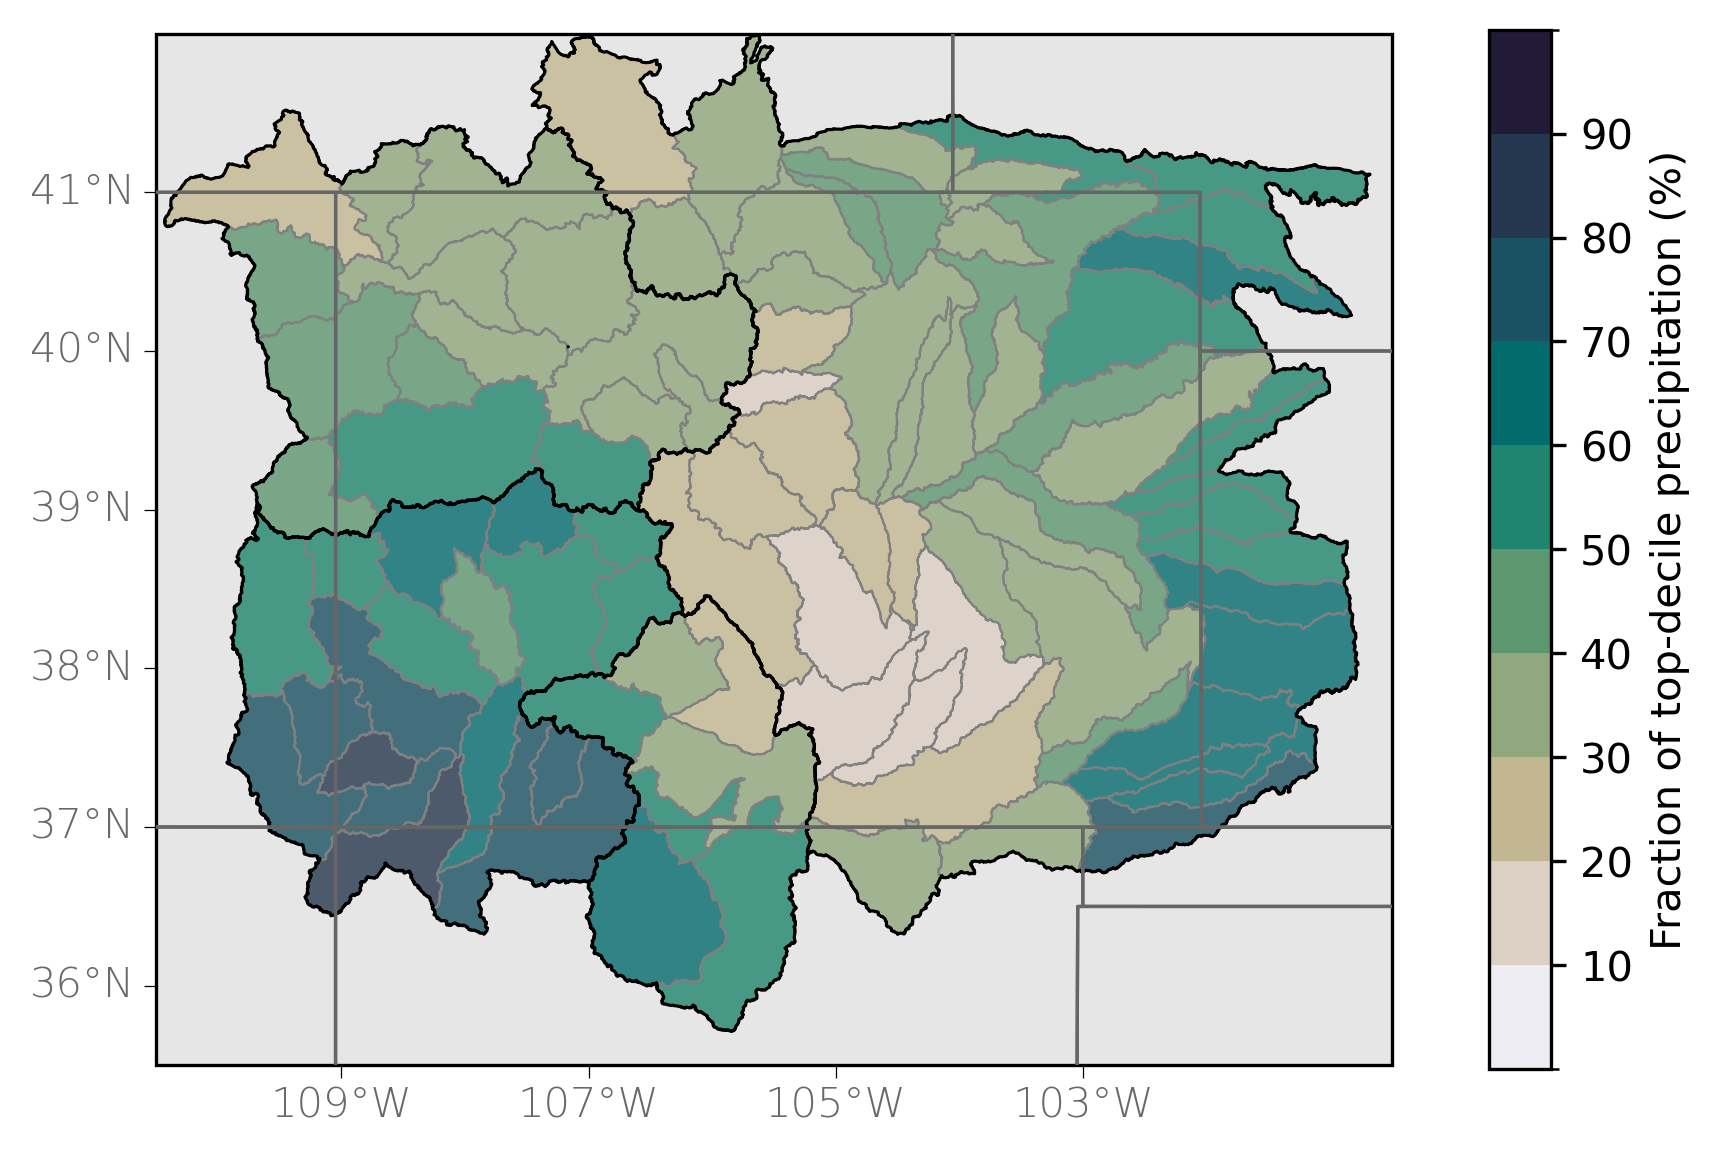

In [13]:
# Set up projection
datacrs = ccrs.PlateCarree()  ## the projection the data is in
mapcrs = ccrs.PlateCarree() ## the projection you want your map displayed in

# Set tick/grid locations
ext1 = [-110.5, -100.5, 35.5, 42.] # extent of CO
dx = np.arange(-109., -102.,2)
dy = np.arange(36, 42,1)

# Create figure
fig = plt.figure(figsize=(6., 4.5))
fig.dpi = 300
fname = path_to_figs + 'choropleth_test_tARgetv4_new_method'
fmt = 'png'

# Grid layout
gs = GridSpec(
    1,
    2,
    height_ratios=[1],
    width_ratios=[1, 0.05],
    wspace=0.15,
    hspace=0.03,
)

# Add color bar axis
cbax = fig.add_subplot(gs[0,-1])
ARDT = 'tARget'

## Add axis for plot
ax = fig.add_subplot(gs[0,0], projection=mapcrs)
ax = draw_basemap(ax, extent=ext1, xticks=dx, yticks=dy,left_lats=True, right_lats=False, bottom_lons=True, mask_ocean=False, coastline=False)

## topo with gray shading
# cs = plot_terrain(ax, ext1)

# add choropleth watershed fraction
cbarticks = [10, 20, 30, 40, 50, 60, 70, 80, 90]
lgnd_kwds={"label": "Fraction of top-decile precipitation (%)", "orientation": "vertical", "ticks": cbarticks}
cmap, norm, bnds = ccmap.cmap_segmented(cmo.rain, np.arange(0, 110, 10))
col_name = 'AR_fraction_extreme_precip'
cf = merged_gdf.plot(ax=ax, column=col_name, cmap=cmap, vmin=0, vmax=80, norm=norm, alpha=0.8, legend=True, cax=cbax, legend_kwds=lgnd_kwds)
polys.plot(ax=ax, edgecolor='grey', color='None', linewidth=0.5, zorder=98)

ax.add_feature(cfeature.STATES, edgecolor='0.4', linewidth=0.8, zorder=199)

## add in region watershed shape - first time full opacity, second low opacity
# opac_lst = [1., 0.9]
# zord_lst = [98, 100]
# lw_lst = [0.75, 0.3]
opac_lst = [1.]
zord_lst = [98]
lw_lst = [0.75]
for (opac, zord, lw) in zip(opac_lst, zord_lst, lw_lst):
    regions.plot(ax=ax, edgecolor='k', color='None', linewidth=lw, zorder=zord, alpha=opac)

        
fig.savefig('%s.%s' %(fname, fmt), bbox_inches='tight', dpi=fig.dpi)